In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten

2026-10-22 14:57:56.584158: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 14:57:56.628335: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-22 14:57:56.629070: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-22 14:57:57.626373: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [3]:
X_train = np.loadtxt('input.csv', delimiter = ',')
Y_train = np.loadtxt('labels.csv', delimiter = ',')
X_test = np.loadtxt('input_test.csv', delimiter = ',')
Y_test = np.loadtxt('labels_test.csv', delimiter = ',')

In [4]:
X_train = X_train.reshape(len(X_train), 100, 100, 3)
Y_train = Y_train.reshape(len(Y_train), 1)

X_test = X_test.reshape(len(X_test), 100, 100, 3)
Y_test = Y_test.reshape(len(Y_test), 1)

X_train = X_train/255.0
X_test = X_test/255.0

In [5]:


print("Shape of X_train: ", X_train.shape)
print("Shape of Y_train: ", Y_train.shape)
print("Shape of X_test: ", X_test.shape)
print("Shape of Y_test: ", Y_test.shape)



Shape of X_train:  (2000, 100, 100, 3)
Shape of Y_train:  (2000, 1)
Shape of X_test:  (400, 100, 100, 3)
Shape of Y_test:  (400, 1)


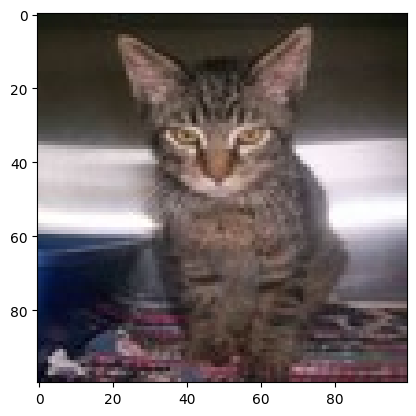

In [6]:
idx = random.randint(0, len(X_train))
plt.imshow(X_train[idx, :])
plt.show()

In [7]:
#MODEL

In [8]:
model = Sequential([
    Conv2D(32, (3,3), activation = 'relu', input_shape = (100, 100, 3)),
    MaxPooling2D((2,2)),
    
    Conv2D(32, (3,3), activation = 'relu'),
    MaxPooling2D((2,2)),
    
    Flatten(),
    Dense(64, activation = 'relu'),
    Dense(1, activation = 'sigmoid')
])


In [9]:
model.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [10]:
model.fit(X_train, Y_train, epochs = 20, batch_size = 64)

2026-10-22 14:58:51.865335: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 240000000 exceeds 10% of free system memory.


Epoch 1/20


2026-10-22 14:58:53.190065: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 78675968 exceeds 10% of free system memory.


 1/32 [..............................] - ETA: 39s - loss: 0.6990 - accuracy: 0.4375

2026-10-22 14:58:53.414607: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 78675968 exceeds 10% of free system memory.
2026-10-22 14:58:53.559814: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 78675968 exceeds 10% of free system memory.


 2/32 [>.............................] - ETA: 7s - loss: 0.9455 - accuracy: 0.4766 

2026-10-22 14:58:53.690755: W tensorflow/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 78675968 exceeds 10% of free system memory.


32/32 [==============================] - 9s 262ms/step - loss: 0.7176 - accuracy: 0.5010
Epoch 2/20
32/32 [==============================] - 8s 259ms/step - loss: 0.6891 - accuracy: 0.5205
Epoch 3/20
32/32 [==============================] - 10s 316ms/step - loss: 0.6247 - accuracy: 0.6675
Epoch 4/20
32/32 [==============================] - 10s 305ms/step - loss: 0.5670 - accuracy: 0.7195
Epoch 5/20
32/32 [==============================] - 9s 285ms/step - loss: 0.5014 - accuracy: 0.7610
Epoch 6/20
32/32 [==============================] - 9s 295ms/step - loss: 0.4628 - accuracy: 0.7805
Epoch 7/20
32/32 [==============================] - 9s 279ms/step - loss: 0.3912 - accuracy: 0.8300
Epoch 8/20
32/32 [==============================] - 8s 264ms/step - loss: 0.3538 - accuracy: 0.8455
Epoch 9/20
32/32 [==============================] - 9s 278ms/step - loss: 0.2840 - accuracy: 0.8880
Epoch 10/20
32/32 [==============================] - 8s 258ms/step - loss: 0.2454 - accuracy: 0.9015
Epoch 11

In [11]:
model.evaluate(X_test, Y_test)

13/13 [==============================] - 0s 27ms/step - loss: 1.2609 - accuracy: 0.6700


[1.2608810663223267, 0.6700000166893005]

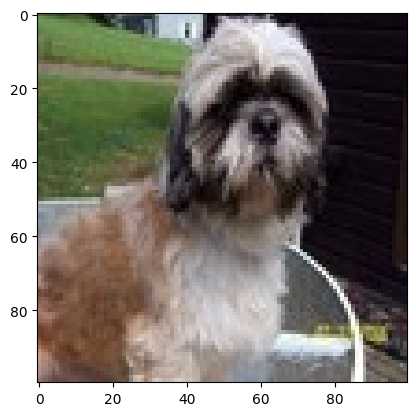

1/1 [==============================] - 0s 72ms/step
Our model says it is a : cat


In [12]:
#MAKING PREDICTION

idx2 = random.randint(0, len(Y_test))
plt.imshow(X_test[idx2, :])
plt.show()

y_pred = model.predict(X_test[idx2, :].reshape(1, 100, 100, 3))
y_pred = y_pred > 0.5

if(y_pred == 0):
    pred = 'dog'
else:
    pred = 'cat'
    
print("Our model says it is a :", pred)

